## INTEGRANTES

Guilherme Santos Nunes – RM558989  
Kaique Rodrigues Zaffarani – RM556677  
Kairo da Silva Silvestre de Carvalho – RM558288  
Pedro Josué Pereira Almeida – RM554913

## Descrição do Projeto

Este projeto aplica **segmentação comportamental** e **modelagem preditiva** sobre
dados transacionais de um e-commerce, com o objetivo de identificar perfis de
clientes e antecipar comportamentos futuros de compra.

### Bases de Dados

Ambas as bases são derivadas do **mesmo arquivo**. A separação é feita por colunas:

- **Base 1 – Histórico Completo:** contém o histórico integral de transações de cada
  cliente. Utilizada **exclusivamente** para a segmentação comportamental via clustering,
  pois captura padrões que só são visíveis depois de várias compras.
- **Base 2 – Primeira Compra:** contém apenas variáveis disponíveis no momento da
  primeira compra do cliente. Utilizada para treinar o modelo de **classificação
  supervisionada**, simulando o cenário em que a loja precisa prever o perfil de um
  novo cliente antes de conhecer seu histórico completo.

### Metodologia

A metodologia RFM (Recência, Frequência, Monetário) segmenta clientes com base no
comportamento de compra:
- **Recência (R):** dias desde a última compra do cliente;
- **Frequência (F):** número de transações registradas;
- **Monetário (M):** valor total gasto na loja.

Os clusters gerados na Base 1 tornam-se a **variável-alvo** do modelo supervisionado
treinado com a Base 2.

### Regra de Data Leakage

> **Nenhuma variável que represente comportamento acumulado do cliente pode ser usada
> como feature na Base 2.** A Base 2 simula o que a loja sabe no momento da primeira
> venda — sem histórico, sem frequência total, sem gasto acumulado.

## Seção 1 – Preparação dos Dados (Base 1)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

### 1.1 Carregamento dos Dados

In [ ]:
# Carregamento do arquivo unico contendo todos os dados dos clientes
df_completo = pd.read_excel("Online Retail.xlsx", header=0)

# Base 1: historico completo - utilizada exclusivamente para segmentacao
base1 = df_completo.copy()

print(f"Dataset carregado: {base1.shape}")
base1.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset carregado: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 1.2 Limpeza de Dados

Remoção de linhas com valores nulos e conversão do identificador do cliente para string.

In [ ]:
# Verificação de nulos por coluna
df_nulos = round(100 * (base1.isnull().sum()) / len(base1), 2)
print("Percentual de valores nulos por coluna:")
print(df_nulos[df_nulos > 0])

# Remoção de registros sem identificação de cliente
base1 = base1.dropna()
base1['CustomerID'] = base1['CustomerID'].astype(str)
print(f"\nDimensões após limpeza: {base1.shape}")

Percentual de valores nulos por coluna:
Description     0.27
CustomerID     24.93
dtype: float64

Dimensões após limpeza: (406829, 8)


### 1.3 Engenharia de Variáveis – Métricas RFM

As três métricas RFM (Recência, Frequência e Monetário) são calculadas por cliente para capturar o comportamento de compra de forma quantitativa.

In [ ]:
# Monetário: valor total gasto por cliente
base1['Valor'] = base1['Quantity'] * base1['UnitPrice']
rfm_m = base1.groupby('CustomerID')['Valor'].sum().reset_index()
rfm_m.columns = ['CustomerID', 'Monetário']
rfm_m.head()

,CustomerID,Monetário
0,12346.0,0.00
1,12347.0,4310.00
2,12348.0,1797.24
3,12349.0,1757.55
4,12350.0,334.40


In [ ]:
# Frequência: número de transações por cliente
rfm_f = base1.groupby('CustomerID')['InvoiceNo'].count().reset_index()
rfm_f.columns = ['CustomerID', 'Frequência']
rfm_f.head()

,CustomerID,Frequência
0,12346.0,2
1,12347.0,182
2,12348.0,31
3,12349.0,73
4,12350.0,17


In [ ]:
# Combinação das métricas Monetário e Frequência
rfm = pd.merge(rfm_m, rfm_f, on='CustomerID', how='inner')
rfm.head()

,CustomerID,Monetário,Frequência
0,12346.0,0.00,2
1,12347.0,4310.00,182
2,12348.0,1797.24,31
3,12349.0,1757.55,73
4,12350.0,334.40,17


In [ ]:
# Recência: dias desde a última compra do cliente
# pd.read_excel já converte datas automaticamente — pd.to_datetime garante o tipo correto
base1['InvoiceDate'] = pd.to_datetime(base1['InvoiceDate'])
data_referencia = base1['InvoiceDate'].max()
base1['DiasDesdeCompra'] = (data_referencia - base1['InvoiceDate'])
base1.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Valor,DiasDesdeCompra
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,373 days 04:24:00
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,373 days 04:24:00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,373 days 04:24:00


In [ ]:
rfm_r = base1.groupby('CustomerID')['DiasDesdeCompra'].min().reset_index()
rfm_r.head()

,CustomerID,DiasDesdeCompra
0,12346.0,325 days 02:33:00
1,12347.0,1 days 20:58:00
2,12348.0,74 days 23:37:00
3,12349.0,18 days 02:59:00
4,12350.0,309 days 20:49:00


In [ ]:
rfm_r['DiasDesdeCompra'] = rfm_r['DiasDesdeCompra'].dt.days
rfm_r.columns = ['CustomerID', 'Recência']
rfm_r.head()

,CustomerID,Recência
0,12346.0,325
1,12347.0,1
2,12348.0,74
3,12349.0,18
4,12350.0,309


In [ ]:
# DataFrame RFM final com as três métricas por cliente
rfm = pd.merge(rfm, rfm_r, on='CustomerID', how='inner')
rfm.head()

,CustomerID,Monetário,Frequência,Recência
0,12346.0,0.00,2,325
1,12347.0,4310.00,182,1
2,12348.0,1797.24,31,74
3,12349.0,1757.55,73,18
4,12350.0,334.40,17,309


### 1.3.1 Construção da Base 2 – Primeira Compra por Cliente

A Base 2 é derivada do **mesmo arquivo**, mas contém apenas variáveis disponíveis
no **momento da primeira compra** de cada cliente — simulando o que a loja saberia
antes de observar qualquer comportamento futuro.

Features extraídas:
- `pais`: país do cliente
- `valor_primeira_compra`: gasto total na primeira fatura
- `qtd_itens_primeira_compra`: quantidade de produtos comprados
- `produtos_distintos`: variedade de itens na primeira compra
- `mes_compra`, `dia_semana`, `hora_compra`: padrão temporal da primeira visita

In [ ]:
# Identificar a primeira fatura (mais antiga) de cada cliente
primeira_fatura_id = (
    base1.sort_values('InvoiceDate')
         .groupby('CustomerID')['InvoiceNo']
         .first()
         .reset_index()
         .rename(columns={'InvoiceNo': 'PrimeiraFatura'})
)

# Filtrar apenas os itens que pertencem à primeira fatura de cada cliente
base2_raw = base1.merge(primeira_fatura_id, on='CustomerID')
base2_raw = base2_raw[base2_raw['InvoiceNo'] == base2_raw['PrimeiraFatura']]

# Agregar métricas da primeira compra por cliente
base2 = (
    base2_raw.groupby('CustomerID').agg(
        pais=('Country', 'first'),
        data_primeira_compra=('InvoiceDate', 'first'),
        valor_primeira_compra=('Valor', 'sum'),
        qtd_itens_primeira_compra=('Quantity', 'sum'),
        produtos_distintos=('StockCode', 'nunique')
    ).reset_index()
)

# Extrair padrão temporal da primeira compra
base2['mes_compra'] = base2['data_primeira_compra'].dt.month
base2['dia_semana'] = base2['data_primeira_compra'].dt.dayofweek
base2['hora_compra'] = base2['data_primeira_compra'].dt.hour
base2 = base2.drop(columns=['data_primeira_compra'])

print(f"Base 1 (segmentação)  : {base1.shape[0]:>6} linhas, {base1.shape[1]} colunas")
print(f"Base 2 (classificação): {base2.shape[0]:>6} clientes, {base2.shape[1]} colunas")
print(f"\nColunas da Base 2: {list(base2.columns)}")
base2.head()

Base 1 (segmentação)  : 406829 linhas, 10 colunas
Base 2 (classificação):   4372 clientes, 8 colunas

Colunas da Base 2: ['CustomerID', 'pais', 'valor_primeira_compra', 'qtd_itens_primeira_compra', 'produtos_distintos', 'mes_compra', 'dia_semana', 'hora_compra']


,CustomerID,pais,valor_primeira_compra,qtd_itens_primeira_compra,produtos_distintos,mes_compra,dia_semana,hora_compra
0,12346.0,United Kingdom,77183.60,74215,1,1,1,10
1,12347.0,Iceland,711.79,319,31,12,1,14
2,12348.0,Finland,892.80,1254,13,12,3,19
3,12349.0,Italy,1757.55,631,73,11,0,9
4,12350.0,Norway,334.40,197,17,2,2,16


### 1.4 Análise de Outliers

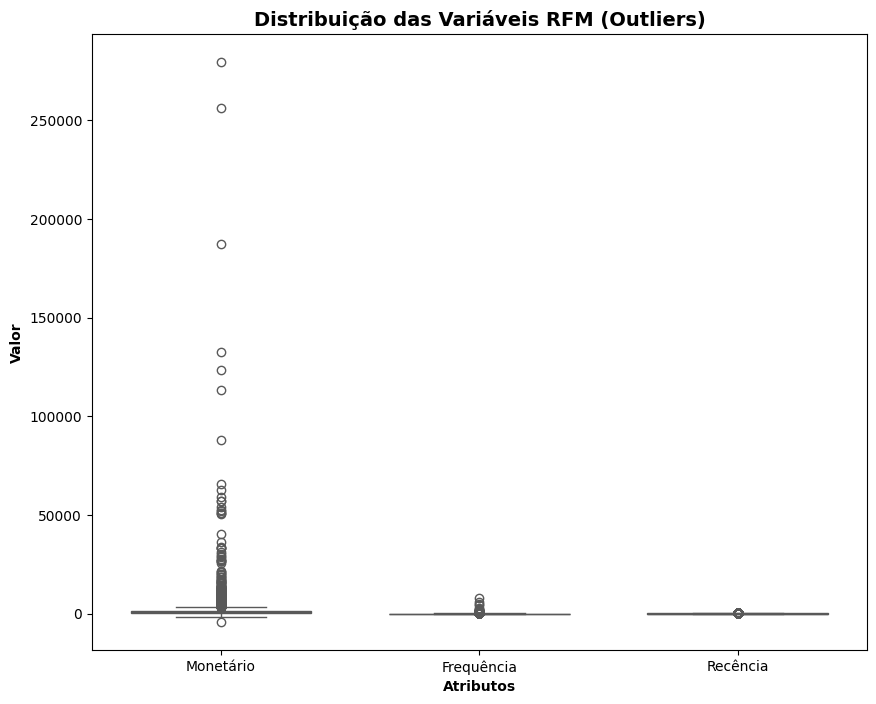

In [ ]:
atributos = ['Monetário', 'Frequência', 'Recência']
plt.rcParams['figure.figsize'] = [10, 8]
sns.boxplot(data=rfm[atributos], orient="v", palette="Set2", whis=1.5, saturation=1, width=0.7)
plt.title("Distribuição das Variáveis RFM (Outliers)", fontsize=14, fontweight='bold')
plt.ylabel("Valor", fontweight='bold')
plt.xlabel("Atributos", fontweight='bold')
plt.show()

In [ ]:
# Remoção de outliers estatísticos
for col in ['Monetário', 'Recência', 'Frequência']:
    Q1 = rfm[col].quantile(0.05)
    Q3 = rfm[col].quantile(0.95)
    IQR = Q3 - Q1
    rfm = rfm[(rfm[col] >= Q1 - 1.5 * IQR) & (rfm[col] <= Q3 + 1.5 * IQR)]

print(f"Dimensões após remoção de outliers: {rfm.shape}")

Dimensões após remoção de outliers: (4293, 4)


### 1.5 Normalização das Variáveis

Padronização das métricas RFM para que diferenças de escala não influenciem o algoritmo de clusterização.

In [ ]:
rfm_df = rfm[['Monetário', 'Frequência', 'Recência']]

scaler = StandardScaler()
rfm_df_scaled = scaler.fit_transform(rfm_df)

rfm_df_scaled = pd.DataFrame(rfm_df_scaled, columns=['Monetário', 'Frequência', 'Recência'])
rfm_df_scaled.head()

,Monetário,Frequência,Recência
0,-0.723738,-0.752888,2.301611
1,1.731617,1.042467,-0.906466
2,0.300128,-0.463636,-0.183658
3,0.277517,-0.044720,-0.738141
4,-0.533235,-0.603275,2.143188


## Seção 2 – Segmentação Comportamental (Clustering)

### 2.1 Definição do Número de Clusters

Dois critérios complementares são usados para definir o número ideal de clusters: o método do cotovelo (Elbow) avalia a inércia, e o Silhouette Score mede a coesão interna dos grupos.

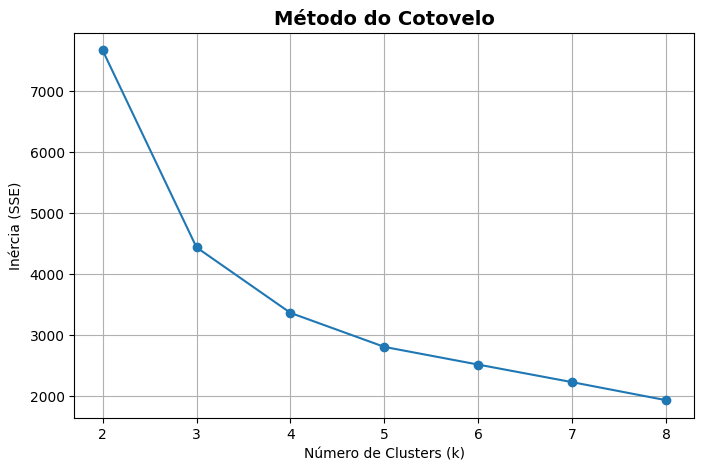

In [ ]:
# Método do Cotovelo (Elbow Method)
inercias = []
range_clusters = [2, 3, 4, 5, 6, 7, 8]

for k in range_clusters:
    kmeans = KMeans(n_clusters=k, max_iter=50, random_state=42)
    kmeans.fit(rfm_df_scaled)
    inercias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range_clusters, inercias, marker='o')
plt.title("Método do Cotovelo", fontsize=14, fontweight='bold')
plt.xlabel("Número de Clusters (k)")
plt.ylabel("Inércia (SSE)")
plt.xticks(range_clusters)
plt.grid(True)
plt.show()

In [ ]:
# Silhouette Score – quanto maior, mais bem definidos os clusters
print("Silhouette Score por número de clusters:\n")
for k in range_clusters:
    kmeans = KMeans(n_clusters=k, max_iter=50, random_state=42)
    kmeans.fit(rfm_df_scaled)
    score = silhouette_score(rfm_df_scaled, kmeans.labels_)
    print(f"  k={k}: {score:.4f}")

Silhouette Score por número de clusters:

  k=2: 0.5395
  k=3: 0.5085
  k=4: 0.4851
  k=5: 0.4617
  k=6: 0.4367
  k=7: 0.4082
  k=8: 0.3227


### 2.2 Modelo K-Means Final

O Silhouette Score máximo ocorre em k=2 (0.54), porém dois segmentos oferecem baixa granularidade para ações comerciais. K=3 mantém score elevado (0.51) com queda marginal de 0.03, e coincide com o ponto de maior variação na inércia (Método do Cotovelo). A escolha de k=3 equilibra qualidade estatística e interpretabilidade de negócio.

In [ ]:
# Criação de modelo definitivo com k=3
kmeans_final = KMeans(n_clusters=3, max_iter=50, random_state=42)
kmeans_final.fit(rfm_df_scaled)

# Coluna Cluster_KMeans se tornará a variável-alvo do modelo supervisionado
rfm['Cluster_KMeans'] = kmeans_final.labels_
rfm.head()

,CustomerID,Monetário,Frequência,Recência,Cluster_KMeans
0,12346.0,0.00,2,325,2
1,12347.0,4310.00,182,1,1
2,12348.0,1797.24,31,74,0
3,12349.0,1757.55,73,18,0
4,12350.0,334.40,17,309,2


/tmp/ipykernel_3386/3867463351.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster_KMeans', y=col, data=rfm, ax=ax, palette='Set2')
/tmp/ipykernel_3386/3867463351.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster_KMeans', y=col, data=rfm, ax=ax, palette='Set2')
/tmp/ipykernel_3386/3867463351.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster_KMeans', y=col, data=rfm, ax=ax, palette='Set2')


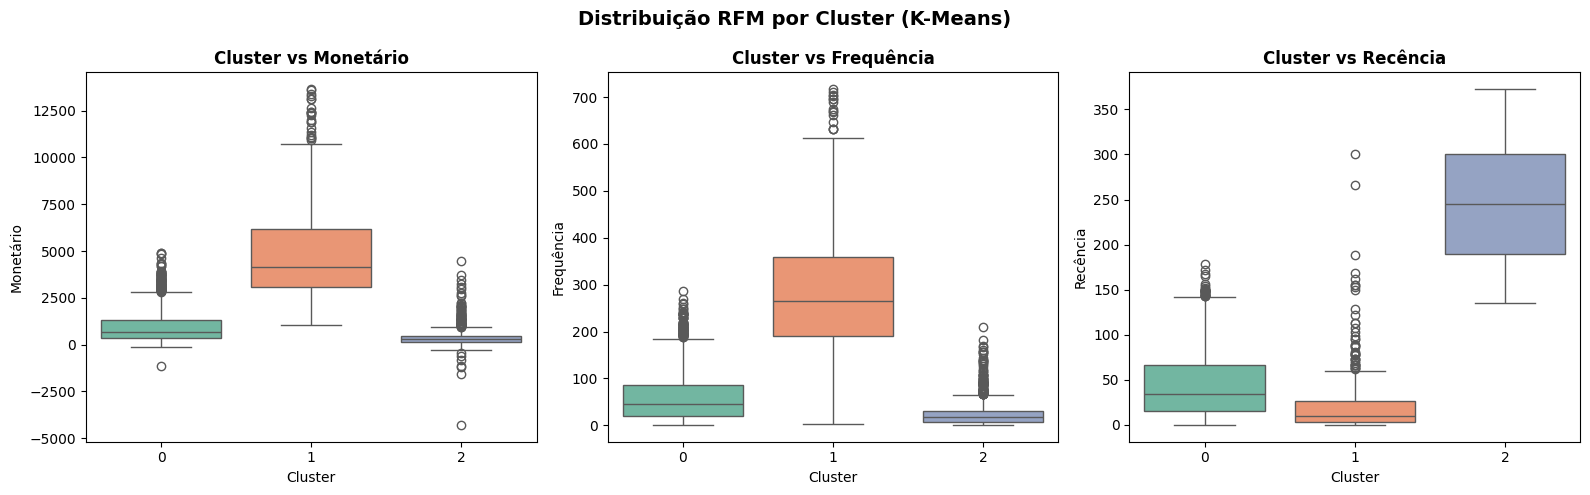

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['Monetário', 'Frequência', 'Recência']):
    sns.boxplot(x='Cluster_KMeans', y=col, data=rfm, ax=ax, palette='Set2')
    ax.set_title(f'Cluster vs {col}', fontweight='bold')
    ax.set_xlabel('Cluster')

plt.suptitle("Distribuição RFM por Cluster (K-Means)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3 Clustering Hierárquico

O clustering hierárquico é usado como validação e comparação. O dendrograma com diferentes métodos de ligação permite visualizar a estrutura natural dos grupos.

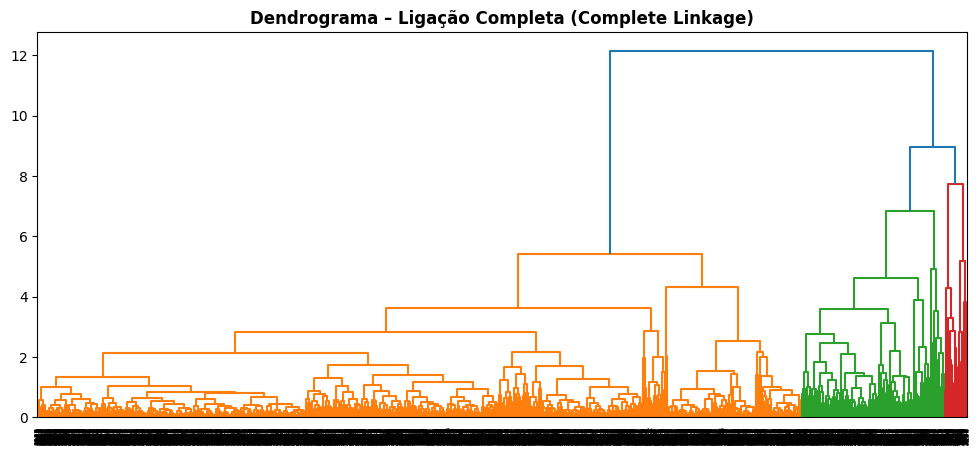

In [ ]:
# Ligação completa (complete linkage)
mergings_complete = linkage(rfm_df_scaled, method="complete", metric='euclidean')
plt.figure(figsize=(12, 5))
dendrogram(mergings_complete)
plt.title("Dendrograma – Ligação Completa (Complete Linkage)", fontweight='bold')
plt.show()

In [ ]:
# Corte do dendrograma em 3 clusters (mesma quantidade do K-Means)
cluster_hier = cut_tree(mergings_complete, n_clusters=3).reshape(-1,)
rfm['Cluster_Hierarquico'] = cluster_hier
rfm.head()

,CustomerID,Monetário,Frequência,Recência,Cluster_KMeans,Cluster_Hierarquico
0,12346.0,0.00,2,325,2,0
1,12347.0,4310.00,182,1,1,1
2,12348.0,1797.24,31,74,0,0
3,12349.0,1757.55,73,18,0,0
4,12350.0,334.40,17,309,2,0


Os dois algoritmos concordam nos perfis centrais — o cliente de alto valor (alto Monetário, alta Frequência, baixa Recência) é classificado no mesmo grupo pelos dois métodos. As divergências ocorrem apenas em clientes de fronteira, que possuem características ambíguas entre dois perfis.

Isso é esperado: algoritmos diferentes tratam casos-limite de formas distintas. O K-Means é adotado como modelo final por apresentar melhor Silhouette Score (0.51 em k=3) e clusters mais equilibrados em tamanho.

## Seção 3 – Interpretação e Nomeação dos Perfis de Negócio

In [ ]:
# Estatísticas médias de cada cluster K-Means
perfil_clusters = rfm.groupby('Cluster_KMeans')[['Monetário', 'Frequência', 'Recência']].mean().round(2)
perfil_clusters.columns = ['Gasto Médio (R$)', 'Frequência Média', 'Recência Média (dias)']
perfil_clusters['Qtd. Clientes'] = rfm.groupby('Cluster_KMeans')['CustomerID'].count()
print("Perfil médio por cluster:\n")
print(perfil_clusters)

Perfil médio por cluster:

                Gasto Médio (R$)  Frequência Média  Recência Média (dias)  \
Cluster_KMeans                                                              
0                         951.73             59.52                   44.5   
1                        4898.74            286.89                   21.7   
2                         388.57             25.50                  248.3   

                Qtd. Clientes  
Cluster_KMeans                 
0                        2726  
1                         499  
2                        1068  


#### Visualização das Médias por Cluster

O gráfico abaixo é a ferramenta direta para nomear os perfis: cada barra mostra
o valor médio normalizado das três métricas RFM por cluster.

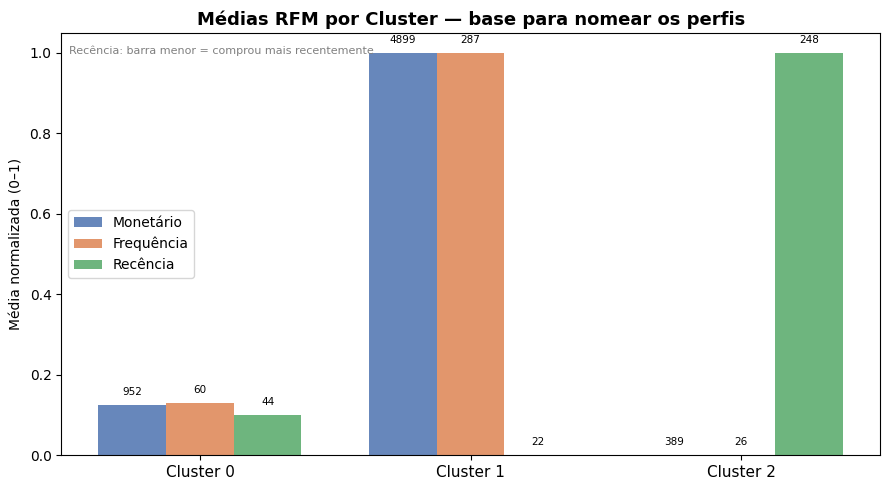


                Monetário  Frequência  Recência
Cluster_KMeans                                 
0                   951.7        59.5      44.5
1                  4898.7       286.9      21.7
2                   388.6        25.5     248.3


In [ ]:
# Medias reais por cluster
medias = rfm.groupby('Cluster_KMeans')[['Monetário', 'Frequência', 'Recência']].mean()

# Normalizar 0-1 para comparar grandezas diferentes no mesmo gráfico
medias_norm = (medias - medias.min()) / (medias.max() - medias.min())

fig, ax = plt.subplots(figsize=(9, 5))
largura = 0.25
x = list(range(len(medias_norm)))
cores = ['#4C72B0', '#DD8452', '#55A868']

for i, col in enumerate(['Monetário', 'Frequência', 'Recência']):
    offset = (i - 1) * largura
    barras = ax.bar([xi + offset for xi in x], medias_norm[col],
                    largura, label=col, color=cores[i], alpha=0.85)
    for bar, val in zip(barras, medias[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
                f'{val:.0f}', ha='center', va='bottom', fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels([f'Cluster {k}' for k in medias_norm.index], fontsize=11)
ax.set_ylabel('Média normalizada (0–1)')
ax.set_title('Médias RFM por Cluster — base para nomear os perfis',
             fontsize=13, fontweight='bold')
ax.legend()
ax.annotate('Recência: barra menor = comprou mais recentemente',
            xy=(0.01, 0.97), xycoords='axes fraction', fontsize=8, va='top', color='gray')
plt.tight_layout()
plt.show()

print()
print(medias.round(1).to_string())

# Mapeamento dos clusters para perfis de negócio com nomes significativos

####   - Alto Monetário + Alta Frequência + Baixa Recência -> **Cliente Premium (mais valioso)**
####   - Médio Monetário + Frequência moderada + Recência média -> **Cliente Potencial (engajado, mas irregular)**
####   - Baixo Monetário + Baixa Frequência + Alta Recência -> **Cliente em Risco (inativo)**

In [ ]:
mapa_perfis = {
    0: "Cliente Potencial",
    1: "Cliente Premium",
    2: "Cliente em Risco"
}

rfm['Perfil'] = rfm['Cluster_KMeans'].map(mapa_perfis)
print(rfm['Perfil'].value_counts())

Perfil
Cliente Potencial    2726
Cliente em Risco     1068
Cliente Premium       499
Name: count, dtype: int64


/tmp/ipykernel_3386/1418345217.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=contagem.index, y=contagem.values, palette='Set2')


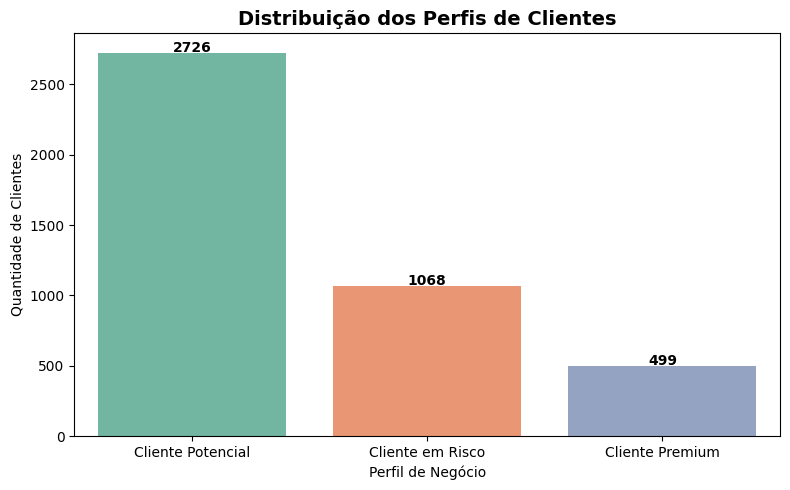

In [ ]:
# Distribuição dos perfis de clientes
plt.figure(figsize=(8, 5))
contagem = rfm['Perfil'].value_counts()
sns.barplot(x=contagem.index, y=contagem.values, palette='Set2')
plt.title("Distribuição dos Perfis de Clientes", fontsize=14, fontweight='bold')
plt.xlabel("Perfil de Negócio")
plt.ylabel("Quantidade de Clientes")
for i, v in enumerate(contagem.values):
    plt.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## Seção 4 – Estratégias de Retenção por Perfil

Com base nos perfis identificados, são apresentadas estratégias comerciais
específicas para cada segmento de cliente.

| Perfil | Características | Estratégias Sugeridas |
|---|---|---|
| **Cliente Premium** | Alta frequência, alto valor, compra recente | Programa de fidelidade exclusivo; acesso antecipado a lançamentos; cupons de recompensa; atendimento prioritário |
| **Cliente Potencial** | Engajamento moderado, valor médio, alguma recência | Campanhas de reativação por e-mail/WhatsApp; ofertas personalizadas; desconto na próxima compra; comunicação segmentada |
| **Cliente em Risco** | Baixa frequência, baixo valor, última compra distante | Contato direto com oferta especial de retorno; pesquisa de satisfação; cupom de desconto agressivo; destaque de novidades relevantes |

## Seção 5 – Classificação Supervisionada (Base 2)

Nesta etapa, os perfis identificados na segmentação tornam-se a **variável-alvo** de um modelo preditivo. A Base 2 contém apenas informações disponíveis no momento da compra, eliminando qualquer risco de data leakage.

### 5.1 Criação da Variável-Alvo

In [ ]:
# A variável-alvo para classificação é o perfil identificado na segmentação
# Extraímos o mapeamento CustomerID → Perfil para unir com a Base 2

alvo = rfm[['CustomerID', 'Cluster_KMeans', 'Perfil']].copy()
alvo.columns = ['CustomerID', 'cluster_id', 'perfil_cliente']

print("Distribuição da variável-alvo:")
print(alvo['perfil_cliente'].value_counts())
print(f"Total de clientes com perfil definido: {len(alvo)}")

Distribuição da variável-alvo:
perfil_cliente
Cliente Potencial    2726
Cliente em Risco     1068
Cliente Premium       499
Name: count, dtype: int64
Total de clientes com perfil definido: 4293


### 5.2 Base 2 – Verificação da Estrutura

A Base 2 foi construída na Seção 1.3.1 a partir da **primeira compra** de cada cliente.
Contém apenas variáveis que existiriam no momento da venda — sem nenhuma informação
sobre comportamento posterior (frequência total, gasto acumulado, recência final, etc.).

In [ ]:
# Confirmação da estrutura da Base 2
print(f'Dimensões: {base2.shape}')
print('\nTipos e nulos:')
print(pd.DataFrame({'tipo': base2.dtypes, 'nulos': base2.isnull().sum()}))
base2.head()

Dimensões: (4372, 8)

Tipos e nulos:
                              tipo  nulos
CustomerID                  object      0
pais                        object      0
valor_primeira_compra      float64      0
qtd_itens_primeira_compra    int64      0
produtos_distintos           int64      0
mes_compra                   int32      0
dia_semana                   int32      0
hora_compra                  int32      0


,CustomerID,pais,valor_primeira_compra,qtd_itens_primeira_compra,produtos_distintos,mes_compra,dia_semana,hora_compra
0,12346.0,United Kingdom,77183.60,74215,1,1,1,10
1,12347.0,Iceland,711.79,319,31,12,1,14
2,12348.0,Finland,892.80,1254,13,12,3,19
3,12349.0,Italy,1757.55,631,73,11,0,9
4,12350.0,Norway,334.40,197,17,2,2,16


In [ ]:
print("Informações gerais da Base 2:")
base2.info()
print("\nEstatísticas descritivas:")
base2.describe()

Informações gerais da Base 2:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4372 entries, 0 to 4371
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 4372 non-null   object 
 1   pais                       4372 non-null   object 
 2   valor_primeira_compra      4372 non-null   float64
 3   qtd_itens_primeira_compra  4372 non-null   int64  
 4   produtos_distintos         4372 non-null   int64  
 5   mes_compra                 4372 non-null   int32  
 6   dia_semana                 4372 non-null   int32  
 7   hora_compra                4372 non-null   int32  
dtypes: float64(1), int32(3), int64(2), object(2)
memory usage: 222.1+ KB

Estatísticas descritivas:


,valor_primeira_compra,qtd_itens_primeira_compra,produtos_distintos,mes_compra,dia_semana,hora_compra
count,4372.000000,4372.000000,4372.000000,4372.000000,4372.000000,4372.000000
mean,402.751835,250.331427,22.382434,7.039341,2.553294,12.572507
std,1288.644085,1199.837523,22.177641,4.005237,1.814844,2.376774
min,-4287.630000,-9360.000000,1.000000,1.000000,0.000000,7.000000
25%,155.332500,75.000000,8.000000,3.000000,1.000000,11.000000
50%,290.830000,147.000000,16.000000,7.000000,2.000000,13.000000
75%,434.545000,270.000000,29.000000,11.000000,4.000000,14.000000
max,77183.600000,74215.000000,262.000000,12.000000,6.000000,20.000000


In [ ]:
# Análise de valores faltantes
nulos_base2 = round(100 * base2.isnull().sum() / len(base2), 2)
nulos_base2 = nulos_base2[nulos_base2 > 0].sort_values(ascending=False)
print("Valores nulos por coluna (%):\n")
print(nulos_base2 if len(nulos_base2) > 0 else "Nenhum valor nulo encontrado.")

Valores nulos por coluna (%):

Nenhum valor nulo encontrado.


### 5.3 Unificação com a Variável-Alvo

In [ ]:
# União da Base 2 com os perfis definidos na segmentação
# Chave de junção: CustomerID (presente em ambas as bases)

base2_alvo = pd.merge(base2, alvo[['CustomerID', 'perfil_cliente']], on='CustomerID', how='inner')

print(f"Registros após junção: {len(base2_alvo)}")
print("Distribuição da variável-alvo na Base 2:")
print(base2_alvo['perfil_cliente'].value_counts())

Registros após junção: 4293
Distribuição da variável-alvo na Base 2:
perfil_cliente
Cliente Potencial    2726
Cliente em Risco     1068
Cliente Premium       499
Name: count, dtype: int64


### 5.4 Pré-processamento para Classificação

In [ ]:
# Remoção de colunas identificadoras (não são features preditivas)
colunas_remover = ['CustomerID', 'cluster_id']
base2_model = base2_alvo.drop(columns=colunas_remover, errors='ignore')

# Codificação de variáveis categóricas (armazena texto ou rótulo e precisa ser convertida para número antes de entrar no modelo)
colunas_categoricas = base2_model.select_dtypes(include=['object']).columns.tolist()
colunas_categoricas = [c for c in colunas_categoricas if c != 'perfil_cliente']

print(f"Variáveis categóricas encontradas: {colunas_categoricas}")

encoders = {}
for col in colunas_categoricas:
    encoders[col] = LabelEncoder()
    base2_model[col] = encoders[col].fit_transform(base2_model[col].astype(str))

# Tratamento de nulos residuais
base2_model = base2_model.fillna(base2_model.median(numeric_only=True))

print(f"Dimensões finais para modelagem: {base2_model.shape}")
base2_model.head()

Variáveis categóricas encontradas: ['pais']
Dimensões finais para modelagem: (4293, 8)


,pais,valor_primeira_compra,qtd_itens_primeira_compra,produtos_distintos,mes_compra,dia_semana,hora_compra,perfil_cliente
0,35,77183.60,74215,1,1,1,10,Cliente em Risco
1,16,711.79,319,31,12,1,14,Cliente Premium
2,12,892.80,1254,13,12,3,19,Cliente Potencial
3,18,1757.55,631,73,11,0,9,Cliente Potencial
4,24,334.40,197,17,2,2,16,Cliente em Risco


### 5.5 Separação Treino/Teste e Treinamento do Modelo

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Separação das features (X) e variável-alvo (y)
X = base2_model.drop(columns=['perfil_cliente', 'cluster_id'], errors='ignore')
y = base2_model['perfil_cliente']

print(f"Features utilizadas ({X.shape[1]} variáveis):")
print(list(X.columns))

# Separação treino (80%) e teste (20%)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nConjunto de treino: {X_treino.shape[0]} amostras")
print(f"Conjunto de teste:  {X_teste.shape[0]} amostras")

# Comparação de modelos candidatos
modelos_candidatos = {
    'Gradient Boosting'  : GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Random Forest'      : RandomForestClassifier(n_estimators=100, random_state=42),
    'Regressão Logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
}

resultados = []
for nome, modelo in modelos_candidatos.items():
    modelo.fit(X_treino, y_treino)
    y_pred_tmp = modelo.predict(X_teste)
    acc  = accuracy_score(y_teste, y_pred_tmp)
    rep  = classification_report(y_teste, y_pred_tmp, output_dict=True)
    f1   = rep['macro avg']['f1-score']
    resultados.append({'Modelo': nome, 'Acurácia': round(acc, 4), 'F1 Macro': round(f1, 4)})

df_resultados = pd.DataFrame(resultados).sort_values('F1 Macro', ascending=False)
print("\nComparação de Modelos:")
print(df_resultados.to_string(index=False))

# Gradient Boosting selecionado como modelo final por melhor F1 Macro e Acurácia
modelo_final = modelos_candidatos['Gradient Boosting']
print("\nModelo final selecionado: Gradient Boosting")

Features utilizadas (7 variáveis):
['pais', 'valor_primeira_compra', 'qtd_itens_primeira_compra', 'produtos_distintos', 'mes_compra', 'dia_semana', 'hora_compra']

Conjunto de treino: 3434 amostras
Conjunto de teste:  859 amostras

Comparação de Modelos:
             Modelo  Acurácia  F1 Macro
  Gradient Boosting    0.6519    0.4741
      Random Forest    0.6333    0.4645
Regressão Logística    0.6380    0.3223

Modelo final selecionado: Gradient Boosting


### 5.6 Avaliação do Modelo (Precision, Recall, F1 score, Support e Matriz de Confusão)

In [ ]:
# Predições no conjunto de teste
y_pred = modelo_final.predict(X_teste)

# Métricas de avaliação
print("=" * 55)
print("RELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 55)
print(classification_report(y_teste, y_pred))

acc = accuracy_score(y_teste, y_pred)
print(f"{'=' * 55}")
print(f"  Acurácia Geral: {acc*100:.2f}%")
print(f"{'=' * 55}")

# Contextualização da acurácia
if acc >= 0.70:
    nivel = "alto"
elif acc >= 0.55:
    nivel = "moderado"
else:
    nivel = "baixo"

print(f"\n  Nível de desempenho: {nivel}")
print(f"  Nota: prever o perfil de um cliente com apenas 7 variáveis")
print(f"  da primeira compra é um problema de sinal fraco por natureza.")
print(f"  A acurácia deve ser interpretada em conjunto com o F1 Macro.")

RELATÓRIO DE CLASSIFICAÇÃO
                   precision    recall  f1-score   support

Cliente Potencial       0.68      0.89      0.77       545
  Cliente Premium       0.50      0.26      0.34       100
 Cliente em Risco       0.51      0.22      0.31       214

         accuracy                           0.65       859
        macro avg       0.56      0.46      0.47       859
     weighted avg       0.62      0.65      0.61       859

  Acurácia Geral: 65.19%

  Nível de desempenho: moderado
  Nota: prever o perfil de um cliente com apenas 7 variáveis
  da primeira compra é um problema de sinal fraco por natureza.
  A acurácia deve ser interpretada em conjunto com o F1 Macro.


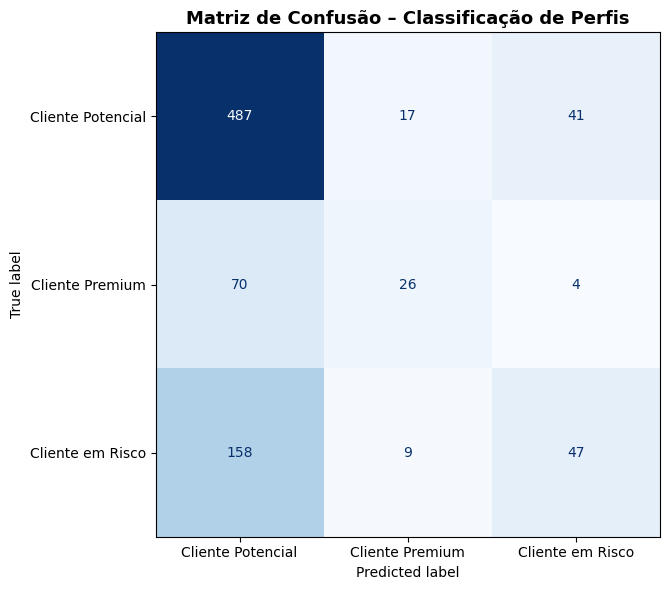

In [ ]:
# Matriz de Confusão
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_teste, y_pred, labels=modelo_final.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo_final.classes_)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title("Matriz de Confusão – Classificação de Perfis", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

/tmp/ipykernel_3386/2645277871.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias.values, y=importancias.index, palette='viridis')


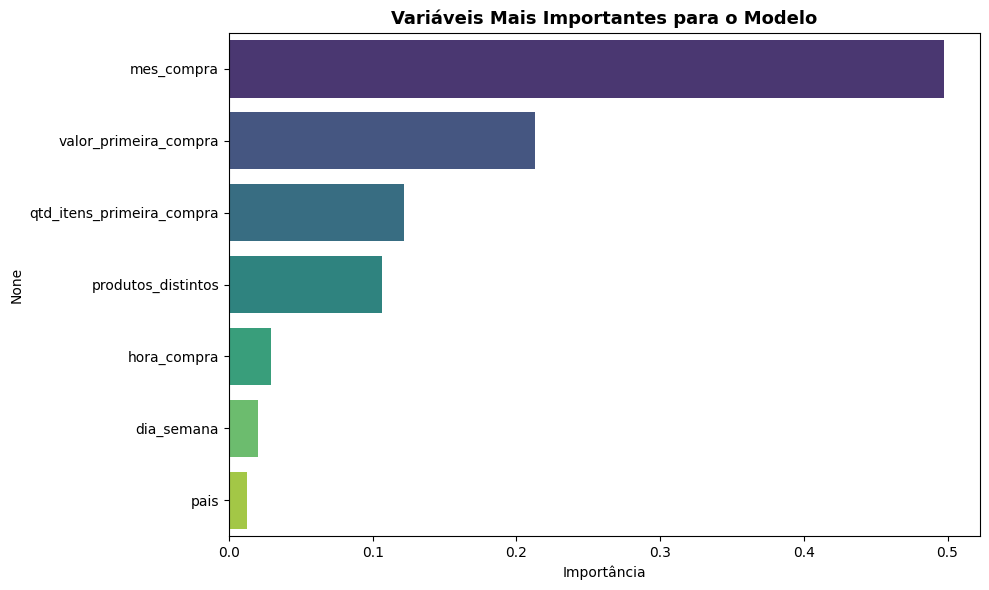

In [ ]:
# Importância das variáveis para a predição
importancias = pd.Series(modelo_final.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=importancias.values, y=importancias.index, palette='viridis')
plt.title("Variáveis Mais Importantes para o Modelo", fontsize=13, fontweight='bold')
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

### 5.7 Inferência – Prevendo o Perfil de um Novo Cliente

Com o modelo treinado, é possível prever o perfil de um novo cliente
usando apenas as informações disponíveis no momento da primeira compra.
O input deve conter exatamente as mesmas colunas usadas no treino.

In [ ]:
# Dados de um novo cliente no momento da primeira compra
# Preencha com os valores reais observados
novo_cliente = pd.DataFrame([{
    'pais'                     : 'United Kingdom',
    'valor_primeira_compra'     : 100,
    'qtd_itens_primeira_compra' : 100,
    'produtos_distintos'        : 50,
    'mes_compra'                : 12,
    'dia_semana'                : 1,
    'hora_compra'               : 15
}])

# Aplicar os mesmos encoders usados no treino
for col in colunas_categoricas:
    novo_cliente[col] = encoders[col].transform(novo_cliente[col].astype(str))

# Garantir a mesma ordem de colunas do treino
novo_cliente = novo_cliente[X.columns]

# Prever perfil e probabilidade por classe
perfil_previsto = modelo_final.predict(novo_cliente)[0]
probabilidades = modelo_final.predict_proba(novo_cliente)[0]

print(f'Perfil previsto: {perfil_previsto}')
print('Probabilidade por perfil:')
for classe, prob in zip(modelo_final.classes_, probabilidades):
    print(f'  {classe}: {prob*100:.1f}%')

Perfil previsto: Cliente em Risco
Probabilidade por perfil:
  Cliente Potencial: 26.4%
  Cliente Premium: 15.0%
  Cliente em Risco: 58.6%


## Seção 6 – Leitura Executiva dos Resultados

### Visão Geral da Segmentação

A aplicação do algoritmo K-Means sobre as métricas RFM resultou na identificação de
**três perfis comportamentais distintos** de clientes:

- **Cliente Premium:** maior valor estratégico. Alto volume de gastos, alta frequência
  de compras e compra recente. Responsável pela maior parcela da receita e com menor
  risco de churn.

- **Cliente Potencial:** grupo intermediário com engajamento moderado e potencial de
  crescimento. Já demonstrou interesse na loja, mas ainda não consolidou um
  relacionamento frequente. Com ações direcionadas, pode migrar para o perfil Premium.

- **Cliente em Risco:** sinais claros de desengajamento. Baixa frequência, baixo valor
  monetário e longa recência indicam clientes que podem estar migrando para concorrentes.
  Exige ação imediata.

---

### Risco de Churn por Segmento

O segmento **Cliente em Risco** apresenta o maior índice de propensão ao abandono.
A elevada recência combinada com baixa frequência histórica são os principais
indicadores de churn iminente. É o segmento que mais demanda ação proativa.

---

### Sensibilidade a Ações Comerciais

O segmento **Cliente Potencial** é o mais receptivo a campanhas. Por já ter histórico
de compra, mas sem consolidar o padrão Premium, responde bem a ofertas personalizadas
e comunicação segmentada. O ROI de campanhas para este segmento tende a ser superior
ao obtido com abordagens genéricas.

### Principais Achados

In [ ]:
# Estatísticas para compor a leitura executiva
dist_perfis = rfm['Perfil'].value_counts()
dist_pct    = (dist_perfis / dist_perfis.sum() * 100).round(1)

acc_final   = accuracy_score(y_teste, y_pred)
rep_dict    = classification_report(y_teste, y_pred, output_dict=True)
f1_macro    = rep_dict['macro avg']['f1-score']

# Classe com pior F1 (onde o modelo mais erra)
f1_por_classe = {k: v['f1-score'] for k, v in rep_dict.items()
                 if k not in ('accuracy', 'macro avg', 'weighted avg')}
classe_dificil = min(f1_por_classe, key=f1_por_classe.get)

# Top 3 features por importância
importancias_top3 = (pd.Series(modelo_final.feature_importances_, index=X.columns)
                       .sort_values(ascending=False)
                       .head(3))

print(f"""
Distribuição dos perfis identificados:
  • Cliente Premium   : {dist_perfis.get('Cliente Premium', 0):>4} clientes ({dist_pct.get('Cliente Premium', 0):.1f}%)
  • Cliente Potencial : {dist_perfis.get('Cliente Potencial', 0):>4} clientes ({dist_pct.get('Cliente Potencial', 0):.1f}%)
  • Cliente em Risco  : {dist_perfis.get('Cliente em Risco', 0):>4} clientes ({dist_pct.get('Cliente em Risco', 0):.1f}%)

Desempenho do modelo preditivo:
  • Acurácia geral : {acc_final*100:.2f}%
  • F1 Macro       : {f1_macro:.4f}
  • Classe mais difícil de prever: "{classe_dificil}" (F1 = {f1_por_classe[classe_dificil]:.4f})

Variáveis mais preditivas:
  1. {importancias_top3.index[0]} ({importancias_top3.iloc[0]*100:.1f}% de importância)
  2. {importancias_top3.index[1]} ({importancias_top3.iloc[1]*100:.1f}% de importância)
  3. {importancias_top3.index[2]} ({importancias_top3.iloc[2]*100:.1f}% de importância)
""")


Distribuição dos perfis identificados:
  • Cliente Premium   :  499 clientes (11.6%)
  • Cliente Potencial : 2726 clientes (63.5%)
  • Cliente em Risco  : 1068 clientes (24.9%)

Desempenho do modelo preditivo:
  • Acurácia geral : 65.19%
  • F1 Macro       : 0.4741
  • Classe mais difícil de prever: "Cliente em Risco" (F1 = 0.3072)

Variáveis mais preditivas:
  1. mes_compra (49.8% de importância)
  2. valor_primeira_compra (21.3% de importância)
  3. qtd_itens_primeira_compra (12.2% de importância)



  O **mês da primeira compra** é o preditor mais relevante não por sazonalidade,
  mas porque funciona como proxy do tempo de histórico disponível no dataset.
  Clientes que entraram nos meses finais do período (ago–nov/2011) não tiveram
  janela temporal suficiente para desenvolver padrão Premium ou Em Risco,
  sendo classificados majoritariamente como Potencial. Esse é um artefato do
  corte temporal dos dados, e não se repetiria em um dataset com janela maior.

  A classe "Cliente em Risco" tende a ser a mais confundida pelo modelo porque suas
  features de primeira compra se sobrepõem com as das demais classes — o
  comportamento que a define (frequência e gasto acumulados) só se manifesta
  ao longo do tempo, e não é observável no momento da compra.

### Aplicação Prática

Esta solução pode ser operacionalizada da seguinte forma:

1. **No momento da primeira compra:** o modelo recebe os dados do novo cliente e
   classifica automaticamente o perfil provável.
2. **Direcionamento de ações:** com o perfil previsto, a equipe de marketing dispara
   a régua de comunicação correspondente — fidelização para Premium previsto,
   engajamento para Potencial, reativação urgente para Em Risco.
3. **Atualização periódica:** a segmentação da Base 1 deve ser reexecutada
   periodicamente para capturar mudanças comportamentais da base ativa.
4. **Monitoramento de migração:** acompanhar clientes que mudam de perfil ao longo
   do tempo é o principal indicador de efetividade das ações de retenção.